# 🌵 Onde furar os poços? — **Chapada do Araripe (PE)**

Alinhado ao **ODS 11.5**, no oeste de Pernambuco — a Chapada do Araripe, na divisa com CE/PI.

Tratamos a estiagem como **alocação de recurso hídrico**: *quantos poços furar, e onde, para atender todas as cidades com o mínimo — sabendo que um poço atende a cidade e suas vizinhas?* É o **Conjunto Dominante Mínimo** (NP-difícil) → **QUBO → Ising → QAOA**.

In [ ]:
# ▶️ NO GOOGLE COLAB: rode esta célula PRIMEIRO (instala o Qiskit).
# (localmente, num venv que já tem o qiskit, pode pular.)
!pip install -q qiskit qiskit-ibm-runtime pylatexenc

## 0. Setup, dados e mapa de fundo

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import os, json, numpy as np, requests
import networkx as nx, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch, Polygon as MplPoly
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp

# ---- identidade visual do cluster (casa com o mapa geral de PE) ----
REGIAO   = "Chapada do Araripe (PE)"
COR      = "#4169d6"       # cor do cluster
FILL     = "#dbe2f8"      # preenchimento dos municípios
VIAVEL   = "#9fb6ec"    # tom claro = solução viável
INVIAVEL = "#e08a7d"     # coral suave = inviável
INK="#264653"; CINZA="#9aa4ab"; INSET_LOC="lower right"
plt.rcParams.update({"figure.facecolor":"white","axes.facecolor":"white","figure.dpi":110,
 "font.size":11,"axes.titlesize":12.5,"axes.titleweight":"bold","axes.labelcolor":INK,
 "axes.edgecolor":"#cfd6db","text.color":INK,"xtick.color":"#6b767d","ytick.color":"#6b767d",
 "axes.spines.top":False,"axes.spines.right":False})
def clean(ax):
    for s in ("top","right"): ax.spines[s].set_visible(False)
    ax.grid(axis="y",color="#eef1f3",lw=1.1); ax.set_axisbelow(True); ax.tick_params(length=0); return ax
def halo(t,w=2.6): t.set_path_effects([pe.withStroke(linewidth=w,foreground="white")]); return t

# ---- dados do cluster ----
cidades=['Araripina', 'Exu', 'Ouricuri', 'Ipubi', 'Santa Filomena', 'Santa Cruz']
coord={'Araripina': (-40.5039, -7.5769), 'Exu': (-39.722, -7.5154), 'Ouricuri': (-40.0833, -7.8844), 'Ipubi': (-40.1494, -7.6535), 'Santa Filomena': (-40.6132, -8.1606), 'Santa Cruz': (-40.3317, -8.2393)}
CODES=set(['2601102', '2605301', '2609907', '2607307', '2612554', '2612455'])
Adj=np.array([[0, 0, 1, 1, 0, 0], [0, 0, 1, 1, 0, 0], [1, 1, 0, 1, 0, 1], [1, 1, 1, 0, 0, 0], [0, 0, 0, 0, 0, 1], [0, 0, 1, 0, 1, 0]])
n=len(cidades)
N={i:sorted([i]+[j for j in range(n) if Adj[i,j]]) for i in range(n)}
POS={c:coord[c] for c in cidades}
EDGES=[(cidades[i],cidades[j]) for i in range(n) for j in range(i+1,n) if Adj[i,j]]

# ---- malha de PE (fundo dos mapas) ----
_p="dados/pe_municipios.geojson"
try:
    if os.path.exists(_p): GJ=json.load(open(_p))
    else:
        GJ=requests.get("https://servicodados.ibge.gov.br/api/v3/malhas/estados/26"
                        "?intrarregiao=municipio&formato=application/vnd.geo+json&qualidade=intermediaria",
                        timeout=90).json()
        os.makedirs("dados",exist_ok=True); json.dump(GJ,open(_p,"w"))
except Exception:
    GJ=None
def _rings(feat):
    g=feat["geometry"]; ps=[g["coordinates"]] if g["type"]=="Polygon" else g["coordinates"]
    return [np.array(p[0]) for p in ps]
if GJ is not None:
    ALLX=[p[0] for f in GJ["features"] for r in _rings(f) for p in r]
    ALLY=[p[1] for f in GJ["features"] for r in _rings(f) for p in r]

def desenhar_mapa(ax, wells=None):
    """Grafo do cluster sobre o mapa de PE. Se wells=lista, marca poços (cheios) x atendidas (anel)."""
    if GJ is not None:
        bg=[]; hi=[]
        for f in GJ["features"]:
            cod=f["properties"]["codarea"]
            for r in _rings(f): (hi if cod in CODES else bg).append(MplPoly(r,closed=True))
        ax.add_collection(PatchCollection(bg,facecolor="#f0f3f4",edgecolor="white",linewidths=0.5,zorder=0))
        ax.add_collection(PatchCollection(hi,facecolor=FILL,edgecolor=COR,linewidths=1.0,alpha=0.9,zorder=1))
    for a,b in EDGES:
        (xa,ya),(xb,yb)=POS[a],POS[b]
        if wells is None:      ax.plot([xa,xb],[ya,yb],color=COR,lw=2.0,alpha=0.5,zorder=3)
        elif a in wells or b in wells: ax.plot([xa,xb],[ya,yb],color=COR,lw=2.6,alpha=0.75,zorder=3)
        else:                  ax.plot([xa,xb],[ya,yb],color="#cdd8de",lw=1.2,zorder=2)
    ys=[p[1] for p in POS.values()]; xs=[p[0] for p in POS.values()]
    dy=(max(ys)-min(ys))*0.05+0.008
    for c,(x,y) in POS.items():
        w=wells is not None and c in wells
        if w:
            ax.scatter(x,y,s=600,color="white",zorder=4)
            ax.scatter(x,y,s=450,color=COR,edgecolors="white",linewidths=2.4,zorder=5)
        elif wells is not None:
            ax.scatter(x,y,s=190,color="white",edgecolors=COR,linewidths=2.4,zorder=5)
        else:
            ax.scatter(x,y,s=430,color="white",zorder=4)
            ax.scatter(x,y,s=320,color=COR,edgecolors="white",linewidths=2.2,zorder=5)
        halo(ax.text(x,y-dy,c,ha="center",va="top",fontsize=9.5,
                     fontweight="bold" if w else "normal",color=INK,zorder=6))
    px=(max(xs)-min(xs))*0.24; py=(max(ys)-min(ys))*0.28
    ax.set_xlim(min(xs)-px,max(xs)+px); ax.set_ylim(min(ys)-py,max(ys)+py)
    ax.set_aspect(1/np.cos(np.radians(np.mean(ys)))); ax.set_axis_off()
    if GJ is not None:
        axin=inset_axes(ax,width="28%",height="28%",loc=INSET_LOC,borderpad=1.1)
        axin.add_collection(PatchCollection([MplPoly(r,closed=True) for f in GJ["features"] for r in _rings(f)],
                            facecolor="#e7ebec",edgecolor="white",linewidths=0.3))
        axin.scatter(np.mean(xs),np.mean(ys),s=90,color=COR,edgecolors="white",linewidths=1.4,zorder=5)
        axin.set_xlim(min(ALLX),max(ALLX)); axin.set_ylim(min(ALLY),max(ALLY))
        axin.set_aspect(1/np.cos(np.radians(np.mean(ys)))); axin.set_axis_off()
        axin.set_title("Pernambuco",fontsize=8,color=CINZA)

print(f"{REGIAO}: {n} cidades | arestas {len(EDGES)} | mapa PE: {'ok' if GJ is not None else 'sem fundo'}")


Chapada do Araripe (PE): 6 cidades | arestas 7 | mapa PE: ok


## 1. O grafo de vizinhança

As 6 cidades sobre o mapa real de Pernambuco (contornos IBGE). Cada aresta liga municípios vizinhos (< 60 km).

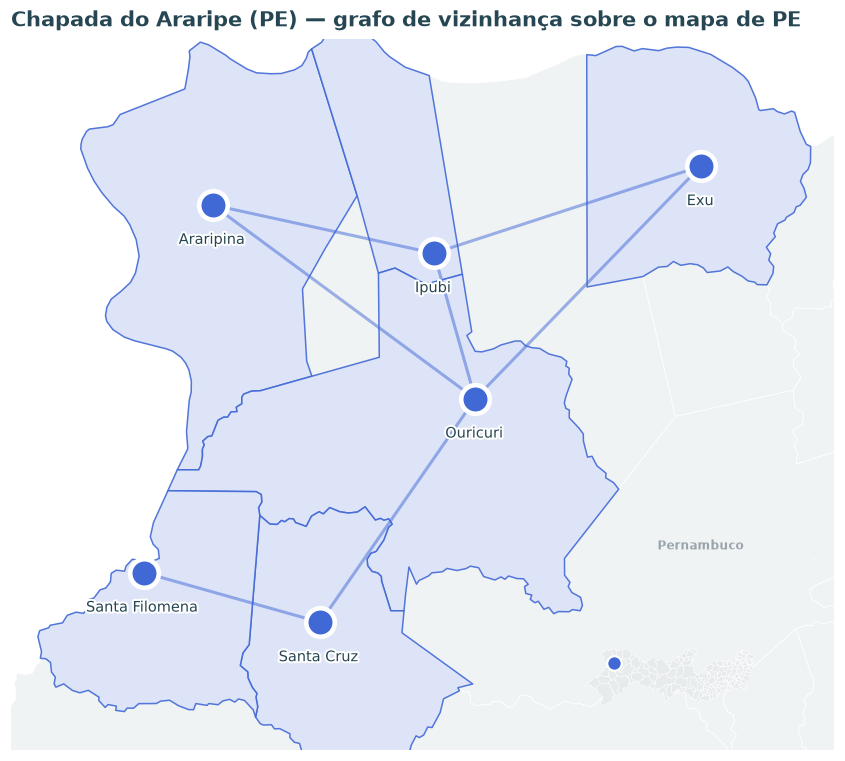

In [2]:
fig,ax=plt.subplots(figsize=(11,8.4))
desenhar_mapa(ax)
ax.set_title(f"{REGIAO} — grafo de vizinhança sobre o mapa de PE",loc="left",fontsize=13.5,color=INK,pad=8)
plt.show()

## 2. Modelagem

$$\min \sum_i x_i \quad\text{s.a.}\quad \sum_{j\in N[i]} x_j\ge 1\;\forall i \qquad\Longrightarrow\qquad H_C=B\sum_i x_i + A\sum_i\prod_{u\in N[i]}(1-x_u)$$

Formulação de **Lucas (2014)** com folgas: ~26 qubits. Versão **compacta** para o QAOA: **6 qubits** (1 por cidade).

In [3]:
A_pen,B_cost=8.0,1.0
def xop(i):
    l=["I"]*n; l[n-1-i]="Z"; return SparsePauliOp.from_list([("I"*n,0.5),("".join(l),-0.5)])
Iop=SparsePauliOp.from_list([("I"*n,1.0)]); Zero=SparsePauliOp.from_list([("I"*n,0.0)])
H_cost=B_cost*sum((xop(i) for i in range(n)),Zero)
for i in range(n):
    prod=Iop
    for u in N[i]: prod=prod@(Iop-xop(u))
    H_cost=H_cost+A_pen*prod
H_cost=H_cost.simplify()
xb=((np.arange(2**n)[:,None]>>np.arange(n))&1)
cov=np.zeros((2**n,n),bool)
for i in range(n): cov[:,i]=xb[:,N[i]].any(1)
energies=(B_cost*xb.sum(1)+A_pen*(~cov).sum(1)).astype(float)
feasible=(~cov).sum(1)==0
print(f"H_C: {len(H_cost)} termos de Pauli em {n} qubits")
print("H_C (Pauli) == energia combinatória ?", np.allclose(np.real(np.diag(H_cost.to_matrix())),energies))

H_C: 36 termos de Pauli em 6 qubits
H_C (Pauli) == energia combinatória ? True


## 3. Solução exata — o gabarito

As $2^{6}=64$ configurações, testadas por força bruta.

ótimo H=2 -> 2 poço(s) | 4 solução(ões) ótima(s):
   • ['Ouricuri', 'Santa Filomena']
   • ['Ipubi', 'Santa Filomena']
   • ['Ouricuri', 'Santa Cruz']
   • ['Ipubi', 'Santa Cruz']


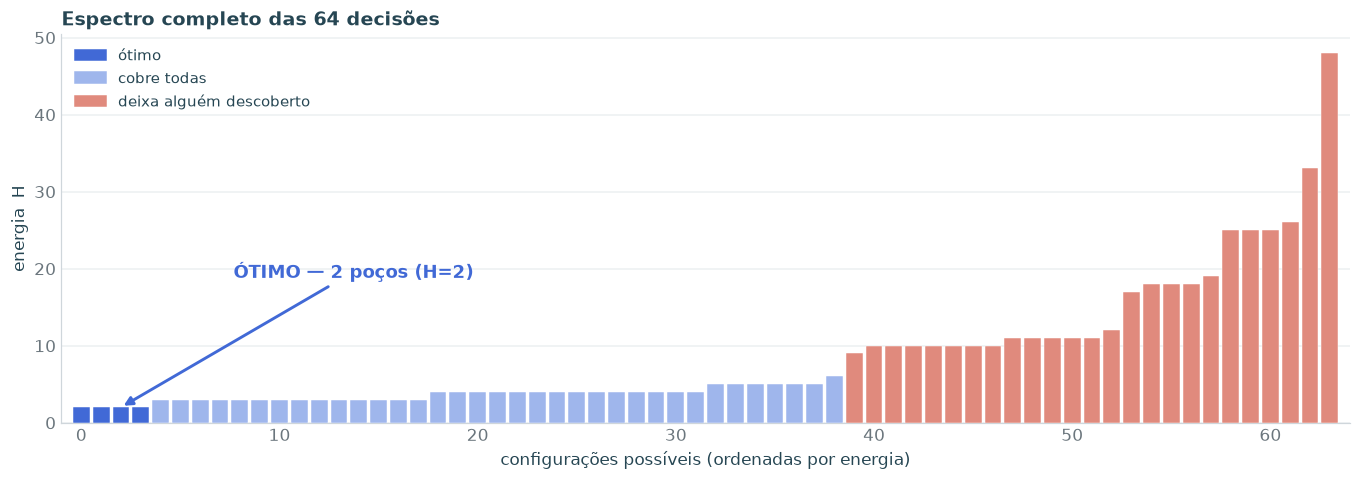

In [4]:
def bits(k): return [(k>>i)&1 for i in range(n)]
def pocos(k): return [cidades[i] for i in range(n) if (k>>i)&1]
def descob(k): return [cidades[i] for i in range(n) if sum(bits(k)[u] for u in N[i])==0]
gmin=energies.min(); otimos=np.where(energies==gmin)[0]; melhor=int(otimos[0])
wells=[cidades[i] for i in range(n) if (melhor>>i)&1]
print(f"ótimo H={gmin:.0f} -> {len(wells)} poço(s) | {len(otimos)} solução(ões) ótima(s):")
for k in otimos: print("   •", pocos(k))

ordem=np.argsort(energies,kind="stable"); nb=xb.sum(1)
def cor_bar(k): return INVIAVEL if not feasible[k] else (COR if energies[k]==gmin else VIAVEL)
fig,ax=plt.subplots(figsize=(12.5,4.5)); clean(ax)
ax.bar(range(2**n),energies[ordem],color=[cor_bar(k) for k in ordem],width=0.85,edgecolor="white",linewidth=0.3,zorder=3)
ax.set_xlim(-1,2**n); ax.set_xlabel("configurações possíveis (ordenadas por energia)"); ax.set_ylabel("energia  H")
ax.set_title(f"Espectro completo das {2**n} decisões",loc="left")
ax.annotate(f"ÓTIMO — {len(wells)} {'poço' if len(wells)==1 else 'poços'} (H={gmin:.0f})",xy=(len(otimos)/2,gmin),
            xytext=(2**n*0.12,gmin+energies.max()*0.35),fontsize=11.5,fontweight="bold",color=COR,
            arrowprops=dict(arrowstyle="-|>",color=COR,lw=1.9))
ax.legend(handles=[Patch(color=COR,label="ótimo"),Patch(color=VIAVEL,label="cobre todas"),
                   Patch(color=INVIAVEL,label="deixa alguém descoberto")],loc="upper left",frameon=False,fontsize=10)
plt.tight_layout(); plt.show()

## 4. QAOA no Qiskit

Superposição → camada de custo $e^{-i\gamma H_C}$ + mixer $R_X$ (circuito mostrado com $p=2$).

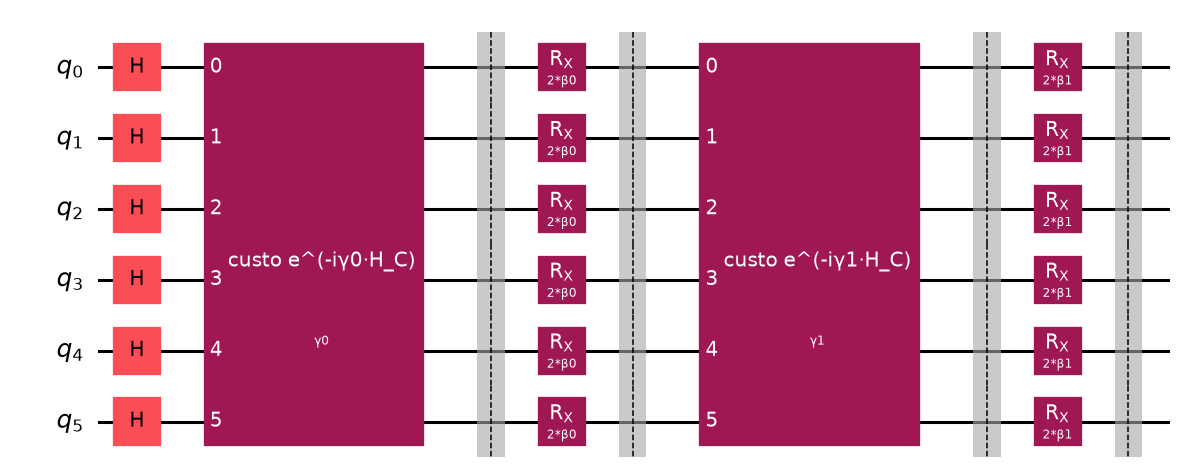

In [5]:
def qaoa_circuit(p):
    g=[Parameter(f"γ{k}") for k in range(p)]; b=[Parameter(f"β{k}") for k in range(p)]
    qc=QuantumCircuit(n); qc.h(range(n))
    for k in range(p):
        ev=PauliEvolutionGate(H_cost,time=g[k]); ev.label=f"custo e^(-iγ{k}·H_C)"
        qc.append(ev,range(n)); qc.barrier()
        for q in range(n): qc.rx(2*b[k],q)
        qc.barrier()
    return qc,g,b
qc_demo,_,_=qaoa_circuit(2)
_=qc_demo.draw("mpl",style="iqp",fold=-1)

### 4.1 Treino e desempenho

$H_C$ é diagonal ⇒ simulador rápido (fases). Varredura de profundidade $p=1..5$.

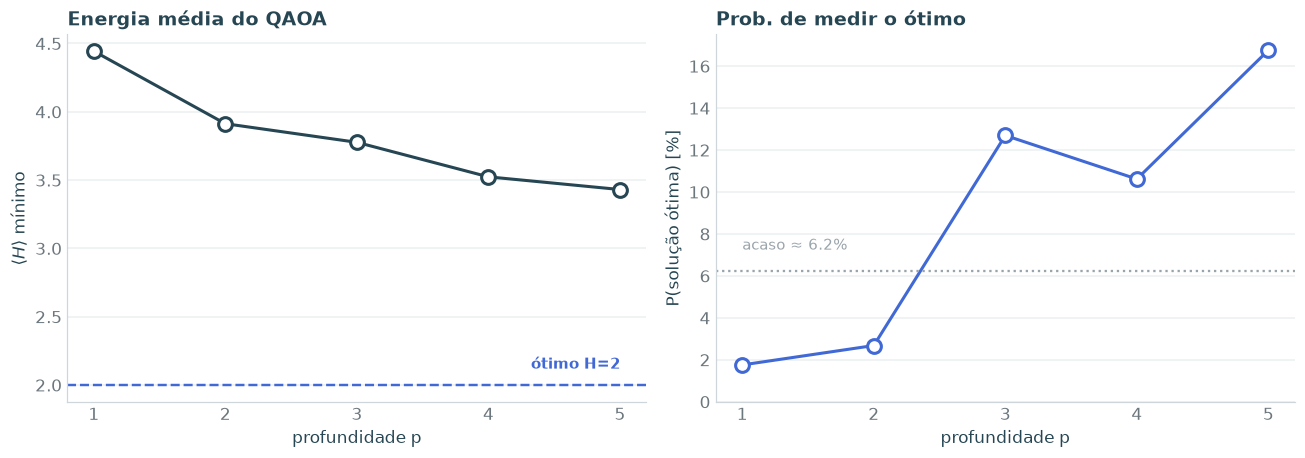

melhor p=5: P(ótimo)=0.168 (acaso 0.062) | par ótimo do QAOA: ['Ipubi', 'Santa Cruz']


In [6]:
def rx_all(state,beta):
    c,s=np.cos(beta),-1j*np.sin(beta); st=state.reshape([2]*n)
    for q in range(n):
        st=np.moveaxis(st,q,0); a0,a1=st[0].copy(),st[1].copy()
        st[0]=c*a0+s*a1; st[1]=s*a0+c*a1; st=np.moveaxis(st,0,q)
    return st.reshape(-1)
def qaoa_probs(v,p):
    g,b=v[:p],v[p:]; state=np.ones(2**n,complex)/np.sqrt(2**n)
    for k in range(p): state=state*np.exp(-1j*g[k]*energies); state=rx_all(state,b[k])
    return np.abs(state)**2
def exp_H(v,p): return float(np.sum(qaoa_probs(v,p)*energies))
def treinar(p,restarts=25,maxiter=300,seed=7):
    rng=np.random.default_rng(seed); best=None
    for _ in range(restarts):
        r=minimize(exp_H,rng.uniform(0,np.pi,2*p),args=(p,),method="COBYLA",options={"maxiter":maxiter})
        if best is None or r.fun<best.fun: best=r
    return best
gmask=energies==gmin; Ps=[1,2,3,4,5]
res={p:treinar(p) for p in Ps}
Popt=[qaoa_probs(res[p].x,p)[gmask].sum() for p in Ps]
Hmed=[res[p].fun for p in Ps]
fig,(a1,a2)=plt.subplots(1,2,figsize=(12,4.3)); clean(a1); clean(a2)
a1.plot(Ps,Hmed,"-",color=INK,lw=2); a1.plot(Ps,Hmed,"o",color="white",mec=INK,mew=2,ms=9)
a1.axhline(gmin,ls="--",color=COR,lw=1.6); a1.set_xticks(Ps)
a1.set_xlabel("profundidade p"); a1.set_ylabel(r"$\langle H\rangle$ mínimo"); a1.set_title("Energia média do QAOA",loc="left")
a1.text(Ps[-1],gmin+0.12,f"ótimo H={gmin:.0f}",color=COR,ha="right",fontsize=9.5,fontweight="bold")
a2.plot(Ps,[100*x for x in Popt],"-",color=COR,lw=2); a2.plot(Ps,[100*x for x in Popt],"o",color="white",mec=COR,mew=2,ms=9)
a2.axhline(100*len(otimos)/2**n,ls=":",color=CINZA); a2.set_xticks(Ps); a2.set_ylim(bottom=0)
a2.set_xlabel("profundidade p"); a2.set_ylabel("P(solução ótima) [%]"); a2.set_title("Prob. de medir o ótimo",loc="left")
a2.text(Ps[0],100*len(otimos)/2**n+1,f"acaso ≈ {100*len(otimos)/2**n:.1f}%",color=CINZA,fontsize=9.5)
plt.tight_layout(); plt.show()
p_star=max(Ps,key=lambda p:qaoa_probs(res[p].x,p)[gmask].sum()); pr=qaoa_probs(res[p_star].x,p_star)
melhor_show=int(max(otimos,key=lambda k:pr[k])); wells_show=[cidades[i] for i in range(n) if (melhor_show>>i)&1]
print(f"melhor p={p_star}: P(ótimo)={pr[gmask].sum():.3f} (acaso {len(otimos)/2**n:.3f}) | par ótimo do QAOA: {wells_show}")

### 4.2 Distribuição de saída

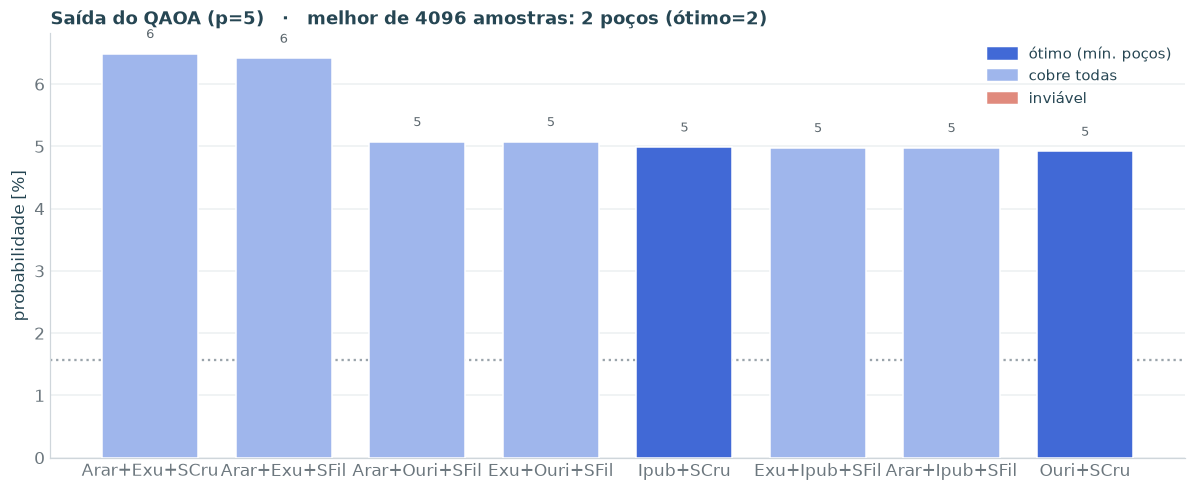

In [7]:
def _ab(nm):
    q=nm.split(); return (q[0][0]+q[1][:3]) if len(q)>1 else nm[:4]   # "SFil"/"SCru", sem colisão
def rot(k):
    ps=pocos(k); return "+".join(_ab(c) for c in ps) if ps else "∅"
def cor_h(k): return COR if energies[k]==gmin else (VIAVEL if feasible[k] else INVIAVEL)
bos=int(min(int(energies[k]) for k in np.random.default_rng(0).choice(2**n,4096,p=pr)))  # melhor de 4096 amostras
topo=np.argsort(pr)[::-1][:8]
fig,ax=plt.subplots(figsize=(11,4.6)); clean(ax)
bars=ax.bar([rot(k) for k in topo],[pr[k]*100 for k in topo],color=[cor_h(k) for k in topo],edgecolor="white",width=0.72,zorder=3)
ax.axhline(100/2**n,ls=":",color=CINZA); ax.set_ylabel("probabilidade [%]")
ax.set_title(f"Saída do QAOA (p={p_star})   ·   melhor de 4096 amostras: {bos} {'poço' if bos==1 else 'poços'} (ótimo={int(gmin)})",loc="left",fontsize=11.5)
for r,k in zip(bars,topo): ax.text(r.get_x()+r.get_width()/2,r.get_height()+0.2,f"{pr[k]*100:.0f}",ha="center",va="bottom",fontsize=8.5,color="#5b666d")
ax.legend(handles=[Patch(color=COR,label="ótimo (mín. poços)"),Patch(color=VIAVEL,label="cobre todas"),Patch(color=INVIAVEL,label="inviável")],
          loc="upper right",frameon=False,fontsize=9.5)
plt.tight_layout(); plt.show()

### 4.3 A solução no mapa

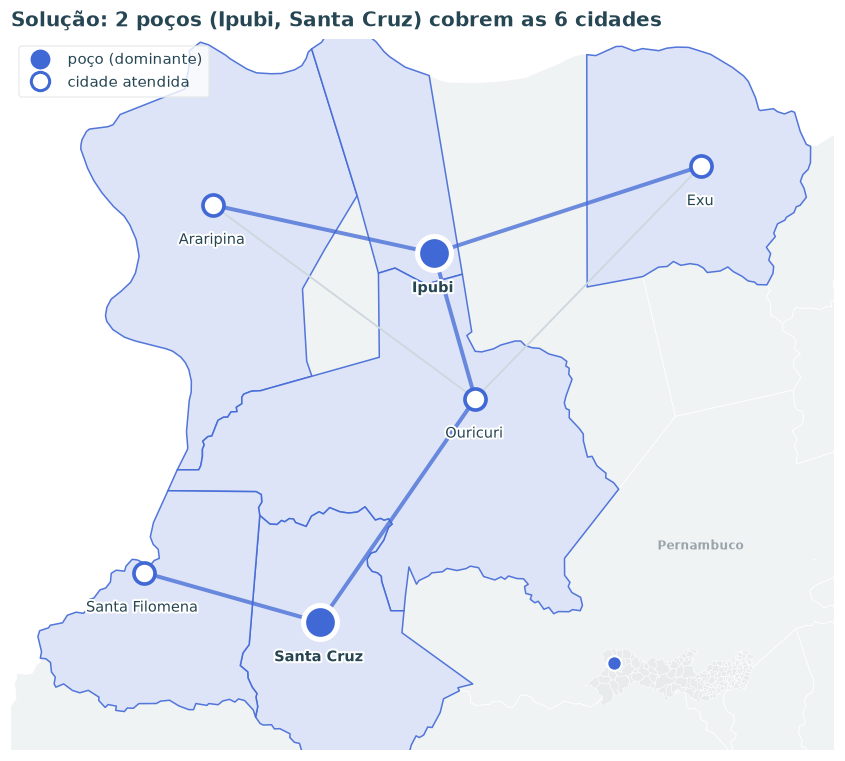

In [8]:
fig,ax=plt.subplots(figsize=(11,8.4))
desenhar_mapa(ax, wells=wells_show)
_np=len(wells_show); _pl="poço" if _np==1 else "poços"; _cv="cobre" if _np==1 else "cobrem"
ax.set_title(f"Solução: {_np} {_pl} ({', '.join(wells_show)}) {_cv} as {n} cidades",
             loc="left",fontsize=13,color=INK,pad=8)
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=COR,markersize=14,label="poço (dominante)"),
                   Line2D([0],[0],marker='o',color='w',markerfacecolor="white",markeredgecolor=COR,markeredgewidth=2,markersize=12,label="cidade atendida")],
          loc="upper left",frameon=True,fontsize=10).get_frame().set_edgecolor("#e6e9ec")
plt.show()

## 5. Conclusão

- Mínimo **2 poços**, com soluções ótimas empatadas — 1 no bloco oeste (Ouricuri/Ipubi) + 1 no par do sul (Santa Filomena/Santa Cruz).
- **Santa Filomena** (grau 1) é o gargalo que força o segundo poço.
- O **QAOA** reencontra os ótimos, concentrando probabilidade neles acima do acaso.

## 6. (Opcional) Rodar em hardware REAL da IBM

Configure o token uma vez (trecho em quantum.ibm.com):
```python
from qiskit_ibm_runtime import QiskitRuntimeService
QiskitRuntimeService.save_account(channel='ibm_quantum_platform', token='SEU_TOKEN', overwrite=True)
```
Otimização já foi no simulador; aqui roda **1 job** (p=1).

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
from qiskit import transpile
from collections import Counter
service=QiskitRuntimeService()
backend=service.least_busy(operational=True, simulator=False, min_num_qubits=n)
print("backend:",backend.name,"| fila:",backend.status().pending_jobs)
p_hw=1; qc_hw,gs,bs=qaoa_circuit(p_hw); qc_hw.measure_all()
qc_hw=qc_hw.assign_parameters(dict(zip(gs+bs,res[p_hw].x)))
qc_t=transpile(qc_hw,backend,optimization_level=3)
print("profundidade:",qc_t.depth(),"| portas 2q:",sum(qc_t.count_ops().get(k,0) for k in ("ecr","cz","cx")))
sampler=SamplerV2(mode=backend)
try: sampler.options.dynamical_decoupling.enable=True
except Exception: pass
job=sampler.run([qc_t],shots=4096); print("job:",job.job_id())
counts=job.result()[0].data.meas.get_counts()
def cds(b): x=[int(c) for c in b[::-1]]; return "+".join(cidades[i][:4] for i in range(n) if x[i]) or "∅"
agg=Counter()
for b,c in counts.items(): agg[cds(b)]+=c
top=agg.most_common(8)
plt.figure(figsize=(11,4)); plt.bar([k for k,_ in top],[v/sum(agg.values())*100 for _,v in top],color=COR,edgecolor="white")
plt.axhline(100/2**n,ls=":",color="gray"); plt.ylabel("frequência [%]"); plt.title(f"Hardware real IBM — {backend.name}")
plt.tight_layout(); plt.show(); print("mais frequente:",top[0])